In [211]:
!git add .
!git commit -m "ml practical prep"
!git push -u origin main
!git status


[main 27b4912] ml practical prep
 3 files changed, 1240 insertions(+), 43 deletions(-)
Enumerating objects: 9, done.
Counting objects: 100% (9/9), done.
Delta compression using up to 8 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (5/5), 48.69 KiB | 16.23 MiB/s, done.
Total 5 (delta 2), reused 0 (delta 0), pack-reused 0 (from 0)
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/NimbalkarYash/machineLearning_practicals.git
   9eba937..27b4912  main -> main
branch 'main' set up to track 'origin/main'.
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [179]:
import pandas as pd
import numpy as nm
import seaborn as sns
import matplotlib.pyplot as plt

In [180]:
df = pd.read_csv("1-uber.csv")

In [181]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [182]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 23.4 MB


In [183]:
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [184]:
#handling the null values

df = df.dropna()




In [185]:
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64

In [186]:
#handling the pick-up timings

df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"]).dt.strftime("%H").astype('float')
df.rename(columns = {"pickup_datetime": "time"}, inplace = True)



In [187]:
df.info()

<class 'pandas.DataFrame'>
Index: 199999 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         199999 non-null  int64  
 1   key                199999 non-null  str    
 2   fare_amount        199999 non-null  float64
 3   time               199999 non-null  float64
 4   pickup_longitude   199999 non-null  float64
 5   pickup_latitude    199999 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    199999 non-null  int64  
dtypes: float64(6), int64(2), str(1)
memory usage: 20.6 MB


In [188]:
#finding out the distance

import math

def findDistance(lan1, lan2, lon1, lon2):
    d1 = lan2 - lan1
    d2 = lon2 - lon1
    d3 = d2**2 + d1**2

    return math.sqrt(d3)


df['distance'] = df.apply(
    lambda row: findDistance(
        row['pickup_latitude'],
        row['dropoff_latitude'],
        row['pickup_longitude'],
        row['dropoff_longitude']
    ), axis = 1
)

In [189]:
df.head()

,Unnamed: 0,key,fare_amount,time,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance
0,24238194,2015-05-07 19:52:06.0000003,7.5,19.0,-73.999817,40.738354,-73.999512,40.723217,1,0.015140
1,27835199,2009-07-17 20:04:56.0000002,7.7,20.0,-73.994355,40.728225,-73.994710,40.750325,1,0.022103
2,44984355,2009-08-24 21:45:00.00000061,12.9,21.0,-74.005043,40.740770,-73.962565,40.772647,1,0.053109
3,25894730,2009-06-26 08:22:21.0000001,5.3,8.0,-73.976124,40.790844,-73.965316,40.803349,3,0.016528
4,17610152,2014-08-28 17:47:00.000000188,16.0,17.0,-73.925023,40.744085,-73.973082,40.761247,5,0.051031


Text(0.5, 1.0, 'fare_amount vs passenger count')

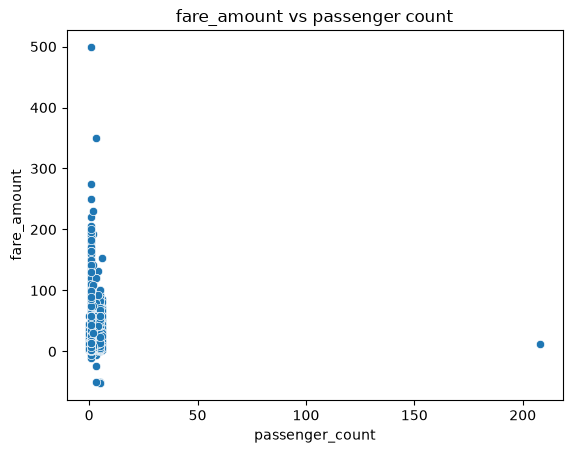

In [190]:
sns.scatterplot(data = df, y = "fare_amount", x = "passenger_count")
plt.title("fare_amount vs passenger count")


In [191]:
#handling the outlier of passenger count

df = df[df['passenger_count'] < 150]

In [192]:
#outlier analysis on other fields


cols = [
    "pickup_longitude",	"pickup_latitude"	,"dropoff_longitude",	"dropoff_latitude"
]


for col in cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - iqr*1.5
    upper_bound = q3 + iqr*1.5

    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

In [193]:
#model fitting

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


In [194]:
df.drop(columns = ['key', 'Unnamed: 0'],  inplace = True)
X = df.drop('fare_amount', axis = 1)
Y = df['fare_amount']

In [195]:
xtrain, xtest, ytrain, ytest = train_test_split(X, Y, test_size = (0.2), random_state = 42)

In [196]:
scaler = StandardScaler()
xtrain_scaled = scaler.fit_transform(xtrain)
xtest_scaled = scaler.transform(xtest)

In [198]:
model1 = LinearRegression()
model1.fit(xtrain_scaled, ytrain)
model1.score(xtest_scaled,ytest)

0.5159111226767117

In [205]:
y_preds = model1.predict(xtest_scaled)

In [206]:
r2_score(ytest, y_preds)

0.5159111226767117

In [207]:
model2 = RandomForestRegressor()

model2.fit(xtrain_scaled, ytrain)

model2.score(xtest_scaled, ytest)

0.5453861432723205

In [210]:
ypreds2 = model2.predict(xtest_scaled)

r2_score(ytest, ypreds2)
root_mean_squared_error(ytest, ypreds2)

3.2261212874105665